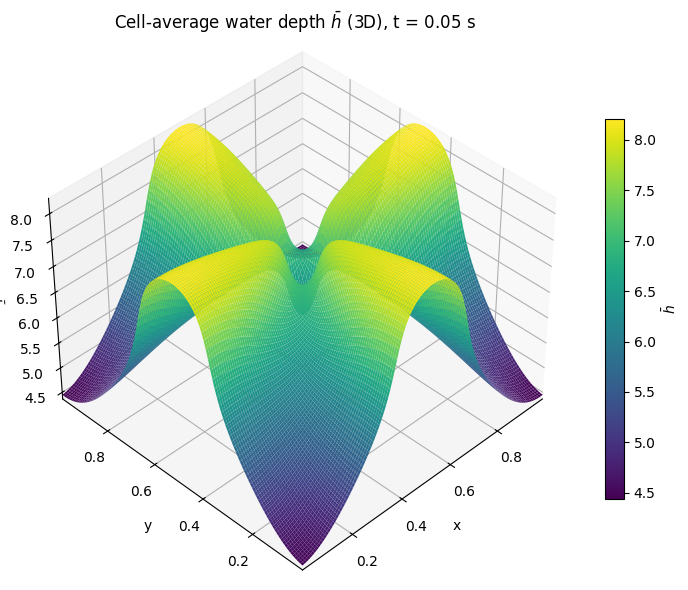

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# ---------- 读取 CSV ----------
data = np.loadtxt("h_cell_128x128.csv", delimiter=",", skiprows=1)
x = data[:, 0]
y = data[:, 1]
h = data[:, 2]

# ---------- 重塑为 2D 网格 ----------
# C++ 写出顺序：(i, j)，i 对应 x，j 对应 y，x 慢、y 快
x_unique = np.unique(x)
y_unique = np.unique(y)
Nx = len(x_unique)
Ny = len(y_unique)

H = h.reshape(Nx, Ny).T                 # → [Ny, Nx]
X, Y = np.meshgrid(x_unique, y_unique)   # X, Y 形状均为 [Ny, Nx]

# ---------- 3D 曲面绘制 ----------
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    X, Y, H,
    cmap="viridis",
    rstride=1, cstride=1,      # 每个网格单元都画
    linewidth=0,
    antialiased=True,
    edgecolor="none",
    alpha=1.0
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel(r"$\bar{h}$")
ax.set_title(r"Cell-average water depth $\bar{h}$ (3D), t = 0.05 s")

# 视角（可按需修改）
ax.view_init(elev=40, azim=-135)

# 等比例显示 XY 平面（matplotlib 3D 对 z 轴等比支持有限，这里固定 XY 范围）
ax.set_xlim(X.min(), X.max())
ax.set_ylim(Y.min(), Y.max())

# colorbar
cb = fig.colorbar(surf, ax=ax, shrink=0.7, aspect=20)
cb.set_label(r"$\bar{h}$")

plt.tight_layout()
# plt.savefig("h_cell_average_3d.png", dpi=200)
plt.show()

In [2]:
import numpy as np
import pandas as pd

# 网格尺寸列表 (后续加入64, 128等只需在此追加即可)
Ns = [4, 8, 16, 32, 64, 128]
data = {}

# 1. 循环读取所有数据并重塑为 NxN 矩阵
for N in Ns:
    df = pd.read_csv(f"h_cell_{N}x{N}.csv")
    data[N] = df['h'].values.reshape((N, N))

# 2. 块平均函数：把细网格降维成粗网格对应的参考解
def block_average(H_fine, N_coarse):
    factor = H_fine.shape[0] // N_coarse
    return H_fine.reshape(N_coarse, factor, N_coarse, factor).mean(axis=(1, 3))

# 3. 循环计算 L1 误差与收敛阶 (以最细的网格 Ns[-1] 为精确解)
N_ref = Ns[-1]
H_ref = data[N_ref]

print(f"{'Mesh':<10} | {'L1 Error':<12} | {'L1 Order':<10}")
print("-" * 40)

E_prev = None

for N in Ns[:-1]:
    # 获取当前网格的参考解
    H_ref_coarse = block_average(H_ref, N)
    
    # 计算 L1 误差 = 绝对误差的平均值 (因为计算域面积为1)
    E_L1 = np.mean(np.abs(data[N] - H_ref_coarse))
    
    # 计算收敛阶
    if E_prev is None:
        order_str = "---"
    else:
        order = np.log(E_prev / E_L1) / np.log(2.0)
        order_str = f"{order:.2f}"
        
    print(f"{N}x{N:<7} | {E_L1:.4e}   | {order_str:<10}")
    
    # 保存当前误差用于下一次循环
    E_prev = E_L1

Mesh       | L1 Error     | L1 Order  
----------------------------------------
4x4       | 2.2001e-01   | ---       
8x8       | 5.9420e-02   | 1.89      
16x16      | 7.4332e-03   | 3.00      
32x32      | 8.4310e-04   | 3.14      
64x64      | 7.3461e-05   | 3.52      


In [3]:
import numpy as np
import pandas as pd

# 网格尺寸列表 (后续加入64, 128等只需在此追加即可)
Ns = [4, 8, 16, 32, 64, 128]
data = {}

# 1. 循环读取所有数据并重塑为 NxN 矩阵
for N in Ns:
    df = pd.read_csv(f"hu_cell_{N}x{N}.csv")
    data[N] = df['hu'].values.reshape((N, N))

# 2. 块平均函数：把细网格降维成粗网格对应的参考解
def block_average(H_fine, N_coarse):
    factor = H_fine.shape[0] // N_coarse
    return H_fine.reshape(N_coarse, factor, N_coarse, factor).mean(axis=(1, 3))

# 3. 循环计算 L1 误差与收敛阶 (以最细的网格 Ns[-1] 为精确解)
N_ref = Ns[-1]
H_ref = data[N_ref]

print(f"{'Mesh':<10} | {'L1 Error':<12} | {'L1 Order':<10}")
print("-" * 40)

E_prev = None

for N in Ns[:-1]:
    # 获取当前网格的参考解
    H_ref_coarse = block_average(H_ref, N)
    
    # 计算 L1 误差 = 绝对误差的平均值 (因为计算域面积为1)
    E_L1 = np.mean(np.abs(data[N] - H_ref_coarse))
    
    # 计算收敛阶
    if E_prev is None:
        order_str = "---"
    else:
        order = np.log(E_prev / E_L1) / np.log(2.0)
        order_str = f"{order:.2f}"
        
    print(f"{N}x{N:<7} | {E_L1:.4e}   | {order_str:<10}")
    
    # 保存当前误差用于下一次循环
    E_prev = E_L1

Mesh       | L1 Error     | L1 Order  
----------------------------------------
4x4       | 1.1485e+00   | ---       
8x8       | 2.8607e-01   | 2.01      
16x16      | 4.2694e-02   | 2.74      
32x32      | 5.4796e-03   | 2.96      
64x64      | 4.8299e-04   | 3.50      


In [4]:
import numpy as np
import pandas as pd

# 网格尺寸列表 (后续加入64, 128等只需在此追加即可)
Ns = [4, 8, 16, 32, 64, 128]
data = {}

# 1. 循环读取所有数据并重塑为 NxN 矩阵
for N in Ns:
    df = pd.read_csv(f"hv_cell_{N}x{N}.csv")
    data[N] = df['hv'].values.reshape((N, N))

# 2. 块平均函数：把细网格降维成粗网格对应的参考解
def block_average(H_fine, N_coarse):
    factor = H_fine.shape[0] // N_coarse
    return H_fine.reshape(N_coarse, factor, N_coarse, factor).mean(axis=(1, 3))

# 3. 循环计算 L1 误差与收敛阶 (以最细的网格 Ns[-1] 为精确解)
N_ref = Ns[-1]
H_ref = data[N_ref]

print(f"{'Mesh':<10} | {'L1 Error':<12} | {'L1 Order':<10}")
print("-" * 40)

E_prev = None

for N in Ns[:-1]:
    # 获取当前网格的参考解
    H_ref_coarse = block_average(H_ref, N)
    
    # 计算 L1 误差 = 绝对误差的平均值 (因为计算域面积为1)
    E_L1 = np.mean(np.abs(data[N] - H_ref_coarse))
    
    # 计算收敛阶
    if E_prev is None:
        order_str = "---"
    else:
        order = np.log(E_prev / E_L1) / np.log(2.0)
        order_str = f"{order:.2f}"
        
    print(f"{N}x{N:<7} | {E_L1:.4e}   | {order_str:<10}")
    
    # 保存当前误差用于下一次循环
    E_prev = E_L1

Mesh       | L1 Error     | L1 Order  
----------------------------------------
4x4       | 1.1485e+00   | ---       
8x8       | 2.8607e-01   | 2.01      
16x16      | 4.2694e-02   | 2.74      
32x32      | 5.4796e-03   | 2.96      
64x64      | 4.8299e-04   | 3.50      
